# PREPARATION

In [396]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Load the dataset
df = pd.read_csv("DataTrain_CoolingLoad.csv")
print("Shape:", df.shape)
print(df.columns.tolist())
df.head()

Shape: (768, 9)
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y']


,X1,X2,X3,X4,X5,X6,X7,X8,Y
0,0.9800,514.5000,294.0000,110.2500,7.0000,2.0000,0.0000,0,21.3300
1,0.9800,514.5000,294.0000,110.2500,7.0000,3.0000,0.0000,0,21.3300
2,0.9800,514.5000,294.0000,110.2500,7.0000,4.0000,0.0000,0,21.3300
3,0.9800,514.5000,294.0000,110.2500,7.0000,5.0000,0.0000,0,21.3300
4,0.9000,563.5000,318.5000,122.5000,7.0000,2.0000,0.0000,0,28.2800


In [397]:
# Check missing values per column
print("Missing values per column:")
print(df.isnull().sum())
print("\nRows with at least one missing value:", df.isnull().any(axis=1).sum())

Missing values per column:
X1    1
X2    5
X3    6
X4    3
X5    0
X6    1
X7    1
X8    0
Y     0
dtype: int64

Rows with at least one missing value: 17


In [398]:
# Missing value handling
# Strategy:
#   1) Rows with missing target Y are dropped (nothing to learn from).
#   2) X2, X3, X4 satisfy the exact identity X2 = X3 + 2*X4, so a single
#      missing value among them can be recovered exactly.
#   3) X1 (Relative Compactness) is one-to-one with X2 in this dataset,
#      so recover it from the X2 -> X1 lookup.
#   4) Remaining gaps: mode for discrete variables (X5, X6, X7, X8),
#      median for continuous ones.
df_clean = df.copy()
df_clean = df_clean.dropna(subset=["Y"]).reset_index(drop=True)

# Step 2: exact reconstruction using X2 = X3 + 2 * X4
m = df_clean["X2"].isna() & df_clean["X3"].notna() & df_clean["X4"].notna()
df_clean.loc[m, "X2"] = df_clean.loc[m, "X3"] + 2 * df_clean.loc[m, "X4"]

m = df_clean["X3"].isna() & df_clean["X2"].notna() & df_clean["X4"].notna()
df_clean.loc[m, "X3"] = df_clean.loc[m, "X2"] - 2 * df_clean.loc[m, "X4"]

m = df_clean["X4"].isna() & df_clean["X2"].notna() & df_clean["X3"].notna()
df_clean.loc[m, "X4"] = (df_clean.loc[m, "X2"] - df_clean.loc[m, "X3"]) / 2

# Step 3: recover X1 from X2 (and X5 from X4) via lookup of the most common partner value
for target, key in [("X1", "X2"), ("X5", "X4")]:
    lookup = (df_clean.dropna(subset=[target, key])
                      .groupby(key)[target]
                      .agg(lambda s: s.mode()[0]))
    m = df_clean[target].isna() & df_clean[key].notna()
    df_clean.loc[m, target] = df_clean.loc[m, key].map(lookup)

# Step 4: fallback imputation
discrete_cols = ["X5", "X6", "X7", "X8"]
continuous_cols = ["X1", "X2", "X3", "X4"]
for col in discrete_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
for col in continuous_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Shape after cleaning:", df_clean.shape)

Remaining missing values: 0
Shape after cleaning: (768, 9)


In [399]:
# Define predictors and target
feature_cols = ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8"]
target_col = "Y"

X = df_clean[feature_cols].astype(float)
y = df_clean[target_col].astype(float)

# Summary statistics (also useful for the report)
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
X1,768.0000,0.7642,0.1058,0.6200,0.6825,0.7500,0.8300,0.9800
X2,768.0000,671.7083,88.0861,514.5000,606.3750,673.7500,741.1250,808.5000
X3,768.0000,318.5000,43.6265,245.0000,294.0000,318.5000,343.0000,416.5000
X4,768.0000,176.6042,45.1660,110.2500,140.8750,183.7500,220.5000,220.5000
X5,768.0000,5.2500,1.7511,3.5000,3.5000,5.2500,7.0000,7.0000
X6,768.0000,3.4961,1.1188,2.0000,2.0000,3.0000,4.0000,5.0000
X7,768.0000,0.2340,0.1332,0.0000,0.1000,0.2500,0.4000,0.4000
X8,768.0000,2.8125,1.5510,0.0000,1.7500,3.0000,4.0000,5.0000
Y,768.0000,24.5878,9.5133,10.9000,15.6200,22.0800,33.1325,48.0300


# PART A: REGRESSION DIAGNOSTICS & ASSUMPTION TESTING


## TASK 1: Multicollinearity Analysis

### 1A

In [400]:
def calculate_vif(X_df):
    """Return a DataFrame of VIF values (a constant is added for correct computation)."""
    X_const = sm.add_constant(X_df, has_constant="add")
    vif_data = pd.DataFrame({
        "Feature": X_const.columns,
        "VIF": [variance_inflation_factor(X_const.values, i)
                for i in range(X_const.shape[1])]
    })
    # Drop the constant row; it is not a predictor
    return vif_data[vif_data["Feature"] != "const"].reset_index(drop=True)

vif_full = calculate_vif(X)
print("VIF of all predictors (X1-X8):")
print(vif_full.sort_values("VIF", ascending=False).to_string(index=False))

VIF of all predictors (X1-X8):
Feature                        VIF
     X2 1,000,799,917,193,443.5000
     X3 1,000,799,917,193,443.5000
     X4 1,000,799,917,193,443.5000
     X1                   105.5249
     X5                    31.2055
     X7                     1.0457
     X8                     1.0457
     X6                     1.0001


### 1B

Variables with severe multicollinearity (VIF > 10):
Feature                        VIF
     X1                   105.5249
     X2 1,000,799,917,193,443.5000
     X3 1,000,799,917,193,443.5000
     X4 1,000,799,917,193,443.5000
     X5                    31.2055

Max |X2 - (X3 + 2*X4)| = 0.0


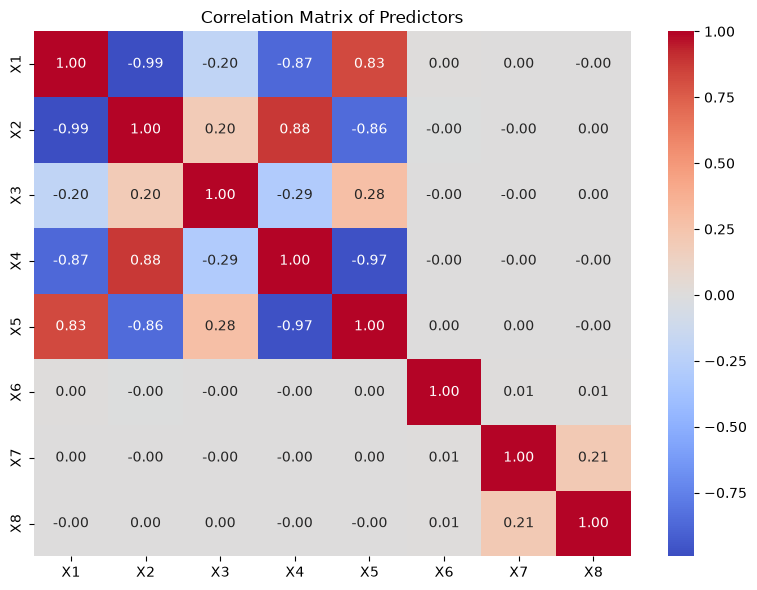

In [401]:
severe = vif_full[vif_full["VIF"] > 10]
print("Variables with severe multicollinearity (VIF > 10):")
print(severe.to_string(index=False))

# Geometric check: Surface Area = Wall Area + 2 * Roof Area
# (floor area equals roof area, so top + bottom = 2 * roof area)
diff = df_clean["X2"] - (df_clean["X3"] + 2 * df_clean["X4"])
print("\nMax |X2 - (X3 + 2*X4)| =", diff.abs().max())

# Correlation heatmap among predictors
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Predictors")
plt.tight_layout()
plt.show()

### 1C

In [402]:
# X2 is an exact linear combination of X3 and X4, so remove it first
X_reduced = X.drop(columns=["X2"])
dropped = ["X2"]

# Iteratively drop the feature with the highest VIF until all VIF <= 10
while True:
    vif_tmp = calculate_vif(X_reduced)
    max_vif = vif_tmp["VIF"].max()
    if max_vif <= 10:
        break
    worst = vif_tmp.loc[vif_tmp["VIF"].idxmax(), "Feature"]
    print(f"Dropping {worst} (VIF = {max_vif:.2f})")
    X_reduced = X_reduced.drop(columns=[worst])
    dropped.append(worst)

print("\nDropped features :", dropped)
print("Remaining features:", X_reduced.columns.tolist())

# Re-evaluate VIF after feature selection
vif_after = calculate_vif(X_reduced)
print("\nVIF after feature selection:")
print(vif_after.to_string(index=False))

Dropping X4 (VIF = 211.94)

Dropped features : ['X2', 'X4']
Remaining features: ['X1', 'X3', 'X5', 'X6', 'X7', 'X8']

VIF after feature selection:
Feature    VIF
     X1 9.2503
     X3 3.1619
     X5 9.6261
     X6 1.0001
     X7 1.0457
     X8 1.0457


In [403]:
# Lasso is scale-sensitive, so standardise the predictors first
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lasso = LassoCV(cv=5, random_state=42, max_iter=10000).fit(X_scaled, y)
lasso_coef = pd.Series(lasso.coef_, index=feature_cols)

print("Best alpha:", round(lasso.alpha_, 5))
print("\nLasso coefficients (standardised features):")
print(lasso_coef.to_string())
print("\nFeatures shrunk to zero:",
      lasso_coef[lasso_coef.abs() < 1e-6].index.tolist())

Best alpha: 0.00852

Lasso coefficients (standardised features):
X1   -5.8054
X2   -2.1253
X3   -0.0000
X4   -3.5157
X5    8.0642
X6    0.1143
X7    1.9475
X8    0.0643

Features shrunk to zero: ['X3']


In [404]:
model_full = sm.OLS(y, sm.add_constant(X)).fit()
model_reduced = sm.OLS(y, sm.add_constant(X_reduced)).fit()

compare = pd.DataFrame({
    "Model": ["Full (X1-X8)", f"Reduced ({', '.join(X_reduced.columns)})"],
    "R2": [model_full.rsquared, model_reduced.rsquared],
    "Adj R2": [model_full.rsquared_adj, model_reduced.rsquared_adj],
    "AIC": [model_full.aic, model_reduced.aic],
})
print(compare.to_string(index=False))
print()
print(model_reduced.summary())

                           Model     R2  Adj R2        AIC
                    Full (X1-X8) 0.8877  0.8866 3,975.5305
Reduced (X1, X3, X5, X6, X7, X8) 0.8844  0.8834 3,995.8979

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.884
Model:                            OLS   Adj. R-squared:                  0.883
Method:                 Least Squares   F-statistic:                     969.9
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:29:15   Log-Likelihood:                -1990.9
No. Observations:                 768   AIC:                             3996.
Df Residuals:                     761   BIC:                             4028.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err

## TASK 2


### 2A

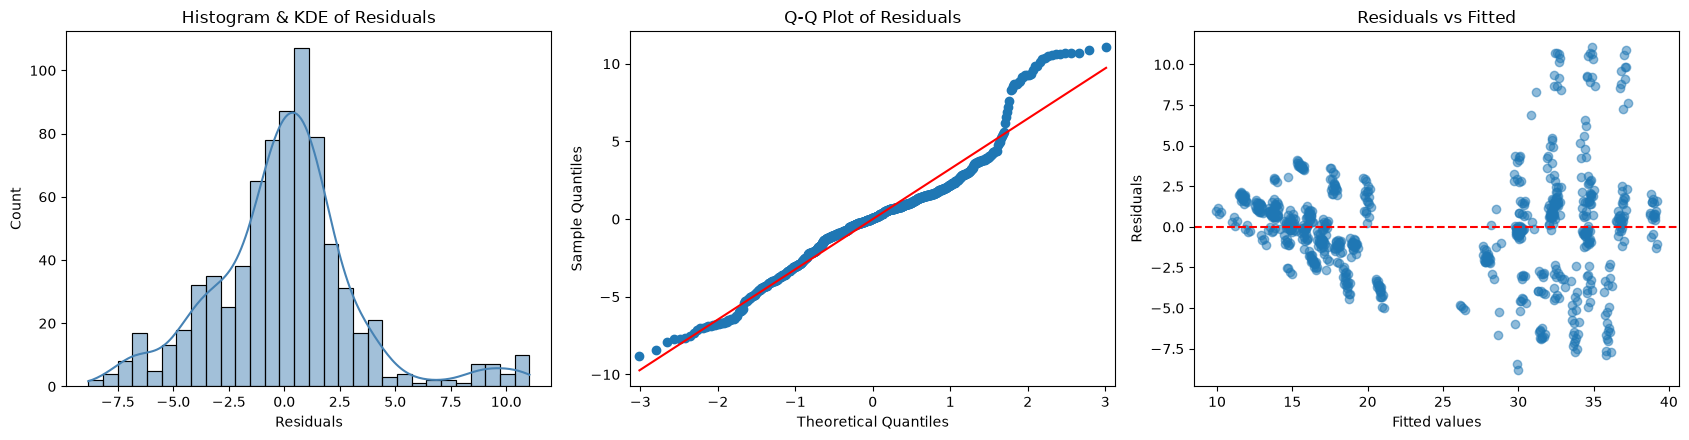

In [405]:
# Use the reduced model (after multicollinearity treatment)
resid = model_reduced.resid
fitted = model_reduced.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Histogram + KDE
sns.histplot(resid, kde=True, bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Histogram & KDE of Residuals")
axes[0].set_xlabel("Residuals")

# Q-Q plot
sm.qqplot(resid, line="s", ax=axes[1])
axes[1].set_title("Q-Q Plot of Residuals")

# Residuals vs fitted (to check heteroscedasticity)
axes[2].scatter(fitted, resid, alpha=0.5)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_xlabel("Fitted values")
axes[2].set_ylabel("Residuals")
axes[2].set_title("Residuals vs Fitted")

plt.tight_layout()
plt.show()

### 2B

In [406]:
def normality_tests(residuals, label=""):
    """Run Shapiro-Wilk and Jarque-Bera tests and report skewness/kurtosis."""
    sw_stat, sw_p = stats.shapiro(residuals)
    jb_stat, jb_p = stats.jarque_bera(residuals)
    print(f"=== Normality tests {label} ===")
    print(f"Shapiro-Wilk : W  = {sw_stat:.4f}, p-value = {sw_p:.4e}")
    print(f"Jarque-Bera  : JB = {jb_stat:.4f}, p-value = {jb_p:.4e}")
    print(f"Skewness = {stats.skew(residuals):.4f}, "
          f"Excess kurtosis = {stats.kurtosis(residuals):.4f}")
    print("Conclusion:", "Residuals look normal (fail to reject H0)"
          if sw_p > 0.05 else "Residuals are NOT normal (reject H0)")
    return sw_p

sw_p_orig = normality_tests(resid, "(original Y)")

# Heteroscedasticity check (Breusch-Pagan)
bp_stat, bp_p, _, _ = het_breuschpagan(resid, model_reduced.model.exog)
print(f"\nBreusch-Pagan: LM = {bp_stat:.4f}, p-value = {bp_p:.4e}")

=== Normality tests (original Y) ===
Shapiro-Wilk : W  = 0.9467, p-value = 5.2195e-16
Jarque-Bera  : JB = 149.0722, p-value = 4.2597e-33
Skewness = 0.5469, Excess kurtosis = 1.8607
Conclusion: Residuals are NOT normal (reject H0)

Breusch-Pagan: LM = 195.6766, p-value = 1.5785e-39


### 2C

Min of Y: 10.9
=== Normality tests (log-transformed Y) ===
Shapiro-Wilk : W  = 0.9733, p-value = 1.2447e-10
Jarque-Bera  : JB = 23.8718, p-value = 6.5510e-06
Skewness = 0.4141, Excess kurtosis = 0.2448
Conclusion: Residuals are NOT normal (reject H0)

Breusch-Pagan (log Y): LM = 125.9825, p-value = 9.0068e-25


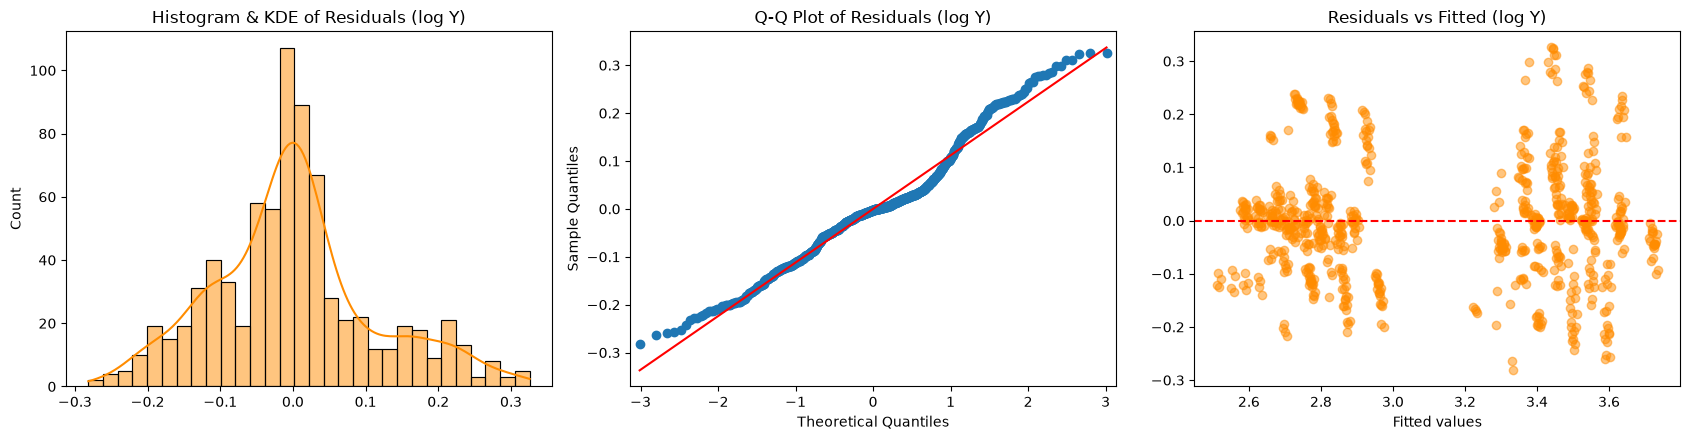


     Model Shapiro p-value  Skewness  Excess kurtosis Breusch-Pagan p
Original Y        5.22e-16    0.5469           1.8607        1.58e-39
    log(Y)        1.24e-10    0.4141           0.2448        9.01e-25


In [407]:
# Log transformation of Y (requires Y > 0)
print("Min of Y:", y.min())

y_log = np.log(y)
model_log = sm.OLS(y_log, sm.add_constant(X_reduced)).fit()
resid_log = model_log.resid

# Re-check normality after transformation
sw_p_log = normality_tests(resid_log, "(log-transformed Y)")

bp_stat_l, bp_p_l, _, _ = het_breuschpagan(resid_log, model_log.model.exog)
print(f"\nBreusch-Pagan (log Y): LM = {bp_stat_l:.4f}, p-value = {bp_p_l:.4e}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(resid_log, kde=True, bins=30, ax=axes[0], color="darkorange")
axes[0].set_title("Histogram & KDE of Residuals (log Y)")

sm.qqplot(resid_log, line="s", ax=axes[1])
axes[1].set_title("Q-Q Plot of Residuals (log Y)")

axes[2].scatter(model_log.fittedvalues, resid_log, alpha=0.5, color="darkorange")
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_xlabel("Fitted values")
axes[2].set_title("Residuals vs Fitted (log Y)")
plt.tight_layout()
plt.show()

# Before vs after summary
summary = pd.DataFrame({
    "Model": ["Original Y", "log(Y)"],
    "Shapiro p-value": [sw_p_orig, sw_p_log],
    "Skewness": [stats.skew(resid), stats.skew(resid_log)],
    "Excess kurtosis": [stats.kurtosis(resid), stats.kurtosis(resid_log)],
    "Breusch-Pagan p": [bp_p, bp_p_l],
})
# Show p-values in scientific notation (the global float format would print 0.0000)
summary_fmt = summary.copy()
summary_fmt["Shapiro p-value"] = summary_fmt["Shapiro p-value"].map("{:.2e}".format)
summary_fmt["Breusch-Pagan p"] = summary_fmt["Breusch-Pagan p"].map("{:.2e}".format)
print()
print(summary_fmt.to_string(index=False))

In [408]:
# Heteroscedasticity-robust (HC3) standard errors:
# coefficients stay identical, only SE / p-values / CIs change
model_robust = sm.OLS(y, sm.add_constant(X_reduced)).fit(cov_type="HC3")

se_compare = pd.DataFrame({
    "coef": model_reduced.params,
    "SE (OLS)": model_reduced.bse,
    "SE (HC3 robust)": model_robust.bse,
    "p (OLS)": model_reduced.pvalues,
    "p (HC3)": model_robust.pvalues,
})
print(se_compare.to_string())

          coef  SE (OLS)  SE (HC3 robust)  p (OLS)  p (HC3)
const  -0.0984    2.9516           3.2815   0.9734   0.9761
X1    -20.0070    3.3721           4.1052   0.0000   0.0000
X3      0.0186    0.0048           0.0051   0.0001   0.0002
X5      5.7331    0.2078           0.2898   0.0000   0.0000
X6      0.1107    0.1048           0.1072   0.2915   0.3020
X7     14.6840    0.9005           0.9112   0.0000   0.0000
X8      0.0460    0.0773           0.0785   0.5519   0.5580


# PART B: MODEL DEVELOPMENT  

In [409]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.4f}".format

## Task 1：Data Preprocessing & EDA

### 1A

In [410]:
# Load the raw data again so that Part B is self-contained
df_raw = pd.read_csv("DataTrain_CoolingLoad.csv")
feature_cols = ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8"]

print("Shape:", df_raw.shape)
print("\nMissing values per column:")
print(df_raw.isnull().sum())

Shape: (768, 9)

Missing values per column:
X1    1
X2    5
X3    6
X4    3
X5    0
X6    1
X7    1
X8    0
Y     0
dtype: int64


In [411]:
# Missing value handling, step 1: structural (row-wise) repair.
# These rules use only the same row (or a fixed design mapping), not training statistics,
# so they cannot leak information from the test set.

# Drop rows with missing target (none expected)
df_rep = df_raw.dropna(subset=["Y"]).reset_index(drop=True)

# Exact identity: Surface Area = Wall Area + 2 * Roof Area  (X2 = X3 + 2*X4)
m = df_rep["X2"].isna() & df_rep["X3"].notna() & df_rep["X4"].notna()
df_rep.loc[m, "X2"] = df_rep.loc[m, "X3"] + 2 * df_rep.loc[m, "X4"]

m = df_rep["X3"].isna() & df_rep["X2"].notna() & df_rep["X4"].notna()
df_rep.loc[m, "X3"] = df_rep.loc[m, "X2"] - 2 * df_rep.loc[m, "X4"]

m = df_rep["X4"].isna() & df_rep["X2"].notna() & df_rep["X3"].notna()
df_rep.loc[m, "X4"] = (df_rep.loc[m, "X2"] - df_rep.loc[m, "X3"]) / 2

# X1 and X2 are one-to-one in this design (12 building shapes)
pairs = df_rep.dropna(subset=["X1", "X2"])
assert pairs.groupby("X2")["X1"].nunique().max() == 1, "X1-X2 mapping is not one-to-one"
x1_map = pairs.drop_duplicates("X2").set_index("X2")["X1"]
m = df_rep["X1"].isna() & df_rep["X2"].notna()
df_rep.loc[m, "X1"] = df_rep.loc[m, "X2"].map(x1_map)

print("Remaining missing values after structural repair:")
print(df_rep.isnull().sum()[lambda s: s > 0])
print("\n(The remaining ones in X6/X7 are filled AFTER the train/test split, using training data only.)")

Remaining missing values after structural repair:
X6    1
X7    1
dtype: int64

(The remaining ones in X6/X7 are filled AFTER the train/test split, using training data only.)


,count,mean,std,min,25%,50%,75%,max
X1,768.0000,0.7642,0.1058,0.6200,0.6825,0.7500,0.8300,0.9800
X2,768.0000,671.7083,88.0861,514.5000,606.3750,673.7500,741.1250,808.5000
X3,768.0000,318.5000,43.6265,245.0000,294.0000,318.5000,343.0000,416.5000
X4,768.0000,176.6042,45.1660,110.2500,140.8750,183.7500,220.5000,220.5000
X5,768.0000,5.2500,1.7511,3.5000,3.5000,5.2500,7.0000,7.0000
X6,767.0000,3.4980,1.1182,2.0000,2.5000,3.0000,4.0000,5.0000
X7,767.0000,0.2342,0.1332,0.0000,0.1000,0.2500,0.4000,0.4000
X8,768.0000,2.8125,1.5510,0.0000,1.7500,3.0000,4.0000,5.0000
Y,768.0000,24.5878,9.5133,10.9000,15.6200,22.0800,33.1325,48.0300


Skewness of Y      : 0.396
Skewness of log(Y) : 0.0557


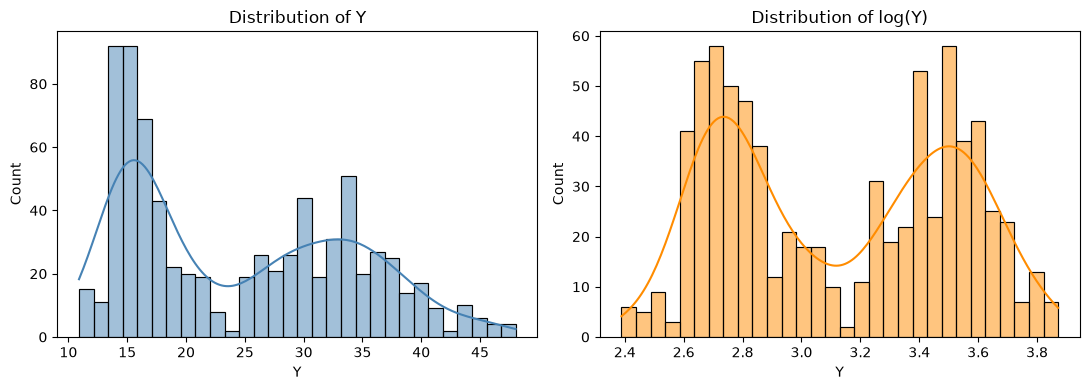

In [412]:
# Summary statistics
display(df_rep.describe().T)

# Why log(Y): compare the target distribution before and after the transformation
print("Skewness of Y      :", round(df_rep["Y"].skew(), 4))
print("Skewness of log(Y) :", round(np.log(df_rep["Y"]).skew(), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_rep["Y"], kde=True, bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Y")
sns.histplot(np.log(df_rep["Y"]), kde=True, bins=30, ax=axes[1], color="darkorange")
axes[1].set_title("Distribution of log(Y)")
plt.tight_layout()
plt.show()

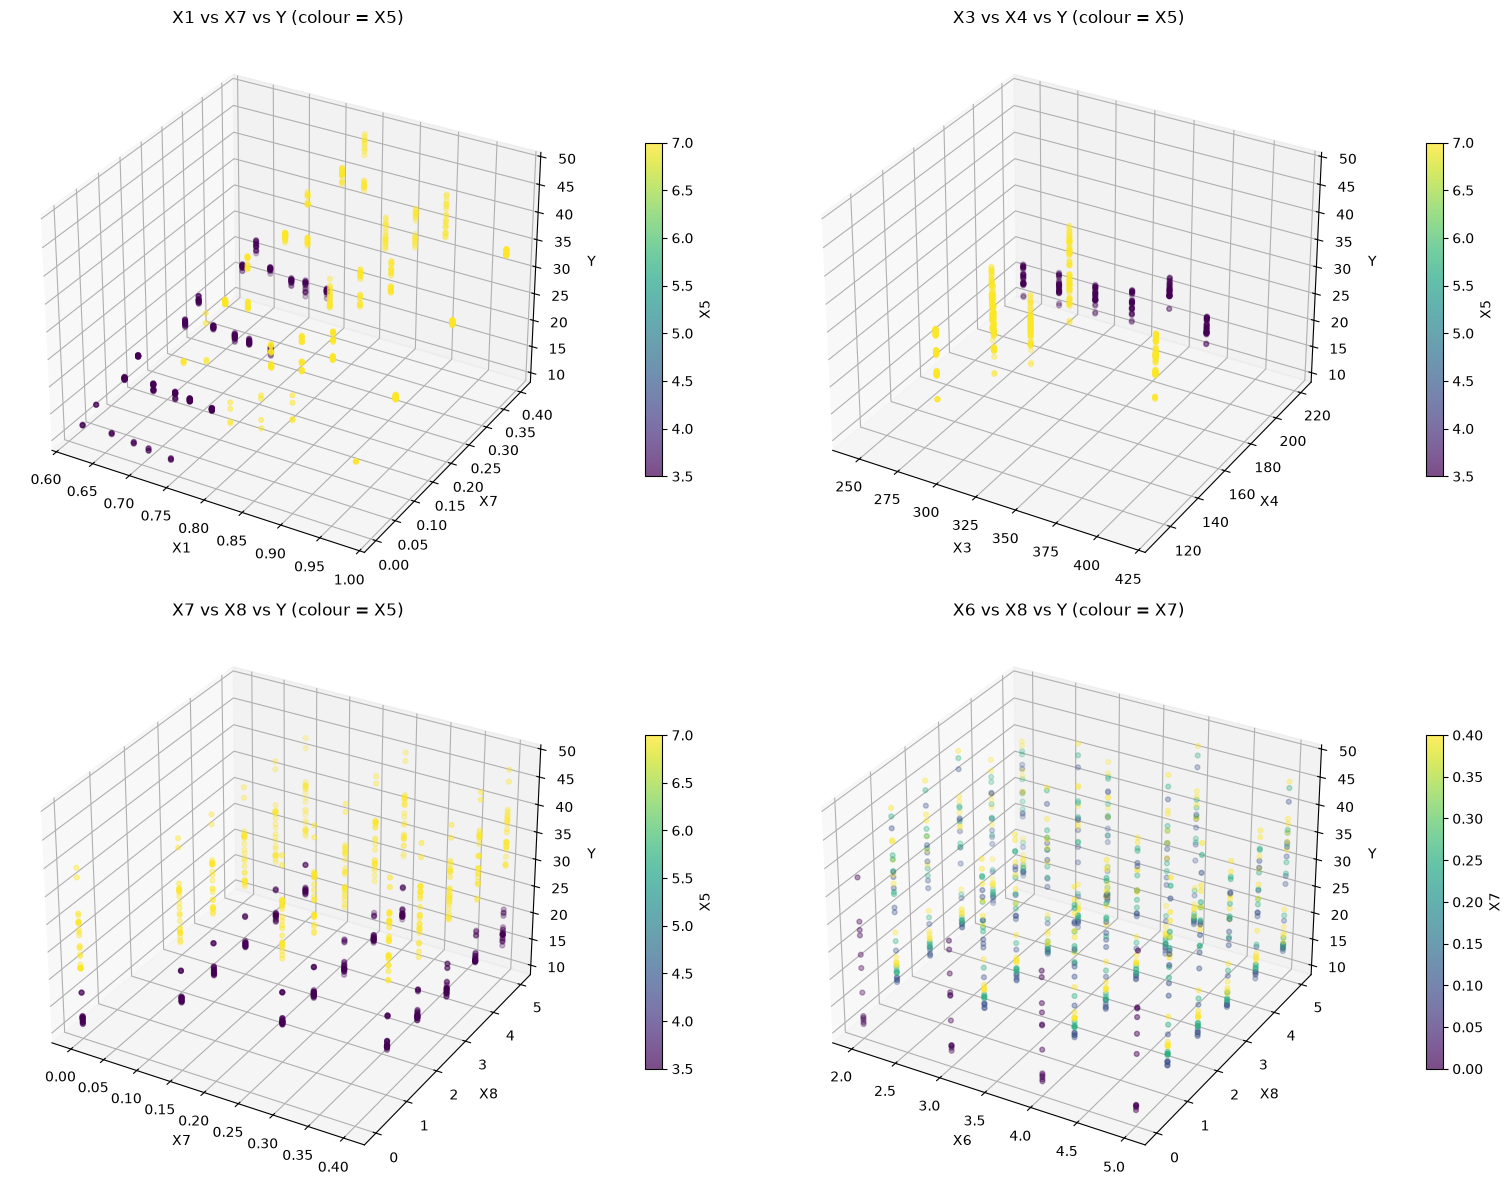

In [413]:
# 3D scatterplots (Y on the vertical axis, a third variable as colour)
plot_df = df_rep.dropna()

def scatter3d(ax, x, y, z, c, title):
    p = ax.scatter(plot_df[x], plot_df[y], plot_df[z], c=plot_df[c],
                   cmap="viridis", s=12, alpha=0.7)
    ax.set_xlabel(x); ax.set_ylabel(y); ax.set_zlabel(z)
    ax.set_title(title)
    plt.colorbar(p, ax=ax, shrink=0.6, pad=0.1, label=c)

fig = plt.figure(figsize=(16, 12))
ax1 = fig.add_subplot(2, 2, 1, projection="3d")
scatter3d(ax1, "X1", "X7", "Y", "X5", "X1 vs X7 vs Y (colour = X5)")
ax2 = fig.add_subplot(2, 2, 2, projection="3d")
scatter3d(ax2, "X3", "X4", "Y", "X5", "X3 vs X4 vs Y (colour = X5)")
ax3 = fig.add_subplot(2, 2, 3, projection="3d")
scatter3d(ax3, "X7", "X8", "Y", "X5", "X7 vs X8 vs Y (colour = X5)")
ax4 = fig.add_subplot(2, 2, 4, projection="3d")
scatter3d(ax4, "X6", "X8", "Y", "X7", "X6 vs X8 vs Y (colour = X7)")
plt.tight_layout()
plt.show()

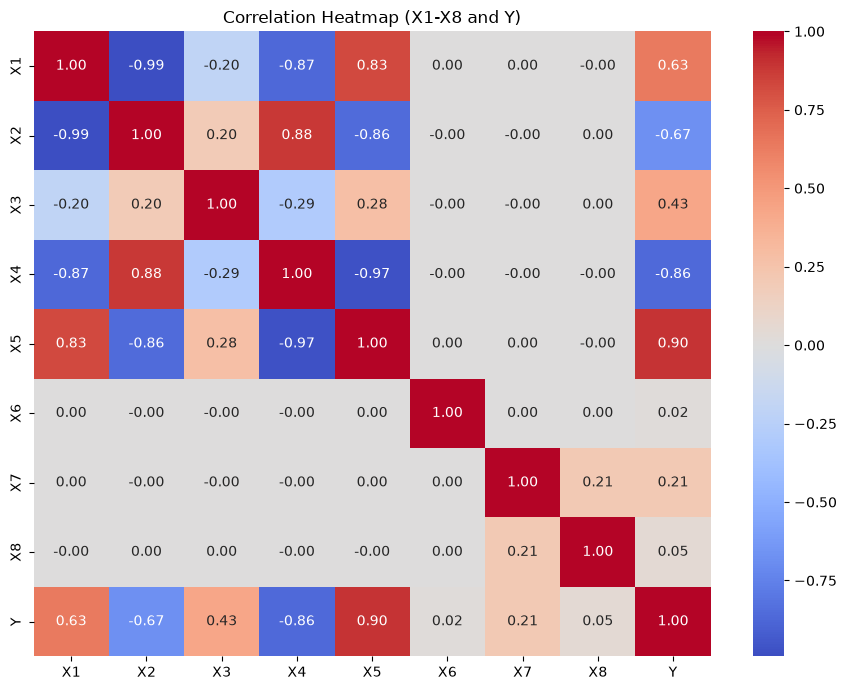

Correlation of each feature with Y (sorted by absolute value):
X5    0.8958
X4   -0.8625
X2   -0.6730
X1    0.6343
X3    0.4271
X7    0.2089
X8    0.0505
X6    0.0158
Name: Y, dtype: float64


In [414]:
# Correlation heatmap between X1-X8 and Y
corr = df_rep[feature_cols + ["Y"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (X1-X8 and Y)")
plt.tight_layout()
plt.show()

print("Correlation of each feature with Y (sorted by absolute value):")
print(corr["Y"].drop("Y").sort_values(key=abs, ascending=False))

### 1B

In [415]:
X = df_rep[feature_cols]
y = df_rep["Y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Missing value handling, step 2: fill the remaining gaps with TRAINING statistics only
fill_values = {"X6": X_train["X6"].mode()[0], "X7": X_train["X7"].median()}
print("Fill values (from training set):", fill_values)
X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)
assert X_train.isnull().sum().sum() == 0 and X_test.isnull().sum().sum() == 0

# Modelling target: log(Y). Y stays in kWh/m2 for evaluation.
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Fill values (from training set): {'X6': np.float64(3.0), 'X7': np.float64(0.25)}
Train: (614, 8) | Test: (154, 8)


In [416]:
def evaluate(model, name, n_params):
    """
    Evaluate a model that predicts log(Y).
    Predictions are back-transformed with exp() so R2, MAE and RMSE are in kWh/m2.
    n_params = number of predictors/terms actually fed to the final regression
    (used for the adjusted R2).
    """
    rows = []
    for split, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        pred_log = model.predict(Xs)
        pred = np.exp(pred_log)
        n = len(ys)
        r2 = r2_score(ys, pred)
        dof = n - n_params - 1
        # Adjusted R2 is undefined when the number of terms >= n - 1
        adj = 1 - (1 - r2) * (n - 1) / dof if dof > 0 else np.nan
        rows.append({
            "Model": name, "Split": split,
            "R2": r2, "Adj R2": adj,
            "MAE": mean_absolute_error(ys, pred),
            "RMSE": np.sqrt(mean_squared_error(ys, pred)),
            "R2 (log scale)": r2_score(np.log(ys), pred_log),
        })
    return pd.DataFrame(rows)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_summary(model):
    """5-fold CV on the training set (log scale), preprocessing is refit inside each fold."""
    r2 = cross_val_score(model, X_train, y_train_log, cv=kf, scoring="r2")
    rmse = -cross_val_score(model, X_train, y_train_log, cv=kf,
                            scoring="neg_root_mean_squared_error")
    return r2.mean(), rmse.mean()

## Task 2：Multiple Linear Regression（Baseline）

### 2A

In [417]:
mlr = LinearRegression().fit(X_train, y_train_log)

print("Rank of X_train:", np.linalg.matrix_rank(X_train.values), "(number of columns = 8)")

coef_table = pd.Series(mlr.coef_, index=feature_cols)
print("\nIntercept:", round(mlr.intercept_, 5))
print(coef_table.to_string())

# Fitted equation on the log scale
terms = " ".join(f"{c:+.5f}*{f}" for f, c in zip(feature_cols, mlr.coef_))
print(f"\nlog(Y) = {mlr.intercept_:.5f} {terms}")
print("Y_hat  = exp( log(Y) )")

Rank of X_train: 7 (number of columns = 8)

Intercept: 3.37211
X1   -1.2452
X2   -0.0009
X3    0.0010
X4   -0.0010
X5    0.1948
X6    0.0021
X7    0.6372
X8    0.0025

log(Y) = 3.37211 -1.24516*X1 -0.00094*X2 +0.00101*X3 -0.00098*X4 +0.19476*X5 +0.00211*X6 +0.63725*X7 +0.00250*X8
Y_hat  = exp( log(Y) )


### 2B

In [418]:
res_mlr = evaluate(mlr, "MLR (baseline)", n_params=8)
print(res_mlr.to_string(index=False))

         Model Split     R2  Adj R2    MAE   RMSE  R2 (log scale)
MLR (baseline) Train 0.8885  0.8870 2.1404 3.1622          0.9178
MLR (baseline)  Test 0.8887  0.8825 2.1144 3.2120          0.9234


## Task 3：Polynomial Regression 

### 3A-3B

In [419]:
# StandardScaler is inside the pipeline for numerical stability of the high-order terms
# (and it is refit inside every CV fold, so there is no leakage).
poly2 = make_pipeline(StandardScaler(),
                      PolynomialFeatures(degree=2, include_bias=False),
                      LinearRegression()).fit(X_train, y_train_log)

poly3 = make_pipeline(StandardScaler(),
                      PolynomialFeatures(degree=3, include_bias=False),
                      LinearRegression()).fit(X_train, y_train_log)

n_terms2 = poly2.named_steps["polynomialfeatures"].n_output_features_
n_terms3 = poly3.named_steps["polynomialfeatures"].n_output_features_
print("Number of polynomial terms  -> degree 2:", n_terms2, "| degree 3:", n_terms3)
print("Training samples:", len(X_train), "| Test samples:", len(X_test))

res_p2 = evaluate(poly2, "Poly degree 2", n_terms2)
res_p3 = evaluate(poly3, "Poly degree 3", n_terms3)

comp = pd.concat([res_mlr, res_p2, res_p3], ignore_index=True)
print()
print(comp.to_string(index=False))

Number of polynomial terms  -> degree 2: 44 | degree 3: 164
Training samples: 614 | Test samples: 154

         Model Split     R2  Adj R2    MAE   RMSE  R2 (log scale)
MLR (baseline) Train 0.8885  0.8870 2.1404 3.1622          0.9178
MLR (baseline)  Test 0.8887  0.8825 2.1144 3.2120          0.9234
 Poly degree 2 Train 0.9726  0.9705 1.0464 1.5671          0.9841
 Poly degree 2  Test 0.9664  0.9528 1.2147 1.7648          0.9813
 Poly degree 3 Train 0.9803  0.9731 0.8745 1.3292          0.9884
 Poly degree 3  Test 0.9718     NaN 1.0878 1.6162          0.9844


### 3C

In [420]:
rows = []
for name, mdl in [("MLR (baseline)", mlr), ("Poly degree 2", poly2), ("Poly degree 3", poly3)]:
    tr = comp[(comp["Model"] == name) & (comp["Split"] == "Train")].iloc[0]
    te = comp[(comp["Model"] == name) & (comp["Split"] == "Test")].iloc[0]
    cv_r2, cv_rmse = cv_summary(mdl)
    rows.append({
        "Model": name,
        "Train R2": tr["R2"], "Test R2": te["R2"],
        "R2 gap (train-test)": tr["R2"] - te["R2"],
        "Test RMSE": te["RMSE"],
        "CV R2 (log)": cv_r2, "CV RMSE (log)": cv_rmse,
    })
balance = pd.DataFrame(rows)
print(balance.to_string(index=False))

         Model  Train R2  Test R2  R2 gap (train-test)  Test RMSE  CV R2 (log)  CV RMSE (log)
MLR (baseline)    0.8885   0.8887              -0.0002     3.2120       0.9153         0.1131
 Poly degree 2    0.9726   0.9664               0.0062     1.7648       0.9819         0.0523
 Poly degree 3    0.9803   0.9718               0.0085     1.6162       0.9839         0.0494


In [421]:
# Optional 1: paired per-fold CV RMSE (log scale) for degree 2 vs degree 3
cv2 = -cross_val_score(poly2, X_train, y_train_log, cv=kf, scoring="neg_root_mean_squared_error")
cv3 = -cross_val_score(poly3, X_train, y_train_log, cv=kf, scoring="neg_root_mean_squared_error")

cv_tab = pd.DataFrame({"Poly degree 2": cv2, "Poly degree 3": cv3})
cv_tab["Difference (deg2 - deg3)"] = cv_tab["Poly degree 2"] - cv_tab["Poly degree 3"]
print(cv_tab.round(4).to_string())
print("\nMean difference:", round(cv_tab["Difference (deg2 - deg3)"].mean(), 4),
      "| SD of difference:", round(cv_tab["Difference (deg2 - deg3)"].std(), 4))

   Poly degree 2  Poly degree 3  Difference (deg2 - deg3)
0         0.0528         0.0524                    0.0003
1         0.0527         0.0465                    0.0062
2         0.0544         0.0516                    0.0028
3         0.0518         0.0515                    0.0003
4         0.0498         0.0451                    0.0047

Mean difference: 0.0029 | SD of difference: 0.0026


## Task 4：MLR + PCA

### 4A

In [422]:
scaler = StandardScaler().fit(X_train)       # fit on training data only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# Variance before scaling: the units are very different, so PCA without scaling would be dominated by X2/X3/X4
print("Variance of each feature BEFORE scaling:")
print(X_train.var().to_string())

print("\nAfter scaling (train): mean ~ 0, std ~ 1")
print(pd.DataFrame({"mean": X_train_s.mean(axis=0), "std": X_train_s.std(axis=0)},
                   index=feature_cols).to_string())

Variance of each feature BEFORE scaling:
X1       0.0111
X2   7,772.3988
X3   1,878.0048
X4   2,021.4230
X5       3.0667
X6       1.2259
X7       0.0180
X8       2.4084

After scaling (train): mean ~ 0, std ~ 1
      mean    std
X1 -0.0000 1.0000
X2 -0.0000 1.0000
X3  0.0000 1.0000
X4 -0.0000 1.0000
X5 -0.0000 1.0000
X6  0.0000 1.0000
X7  0.0000 1.0000
X8 -0.0000 1.0000


### 4B

     Eigenvalue  Explained ratio  Cumulative ratio
PC1      3.7123           0.4633            0.4633
PC2      1.2531           0.1564            0.6197
PC3      1.1999           0.1497            0.7694
PC4      0.9954           0.1242            0.8936
PC5      0.7956           0.0993            0.9929
PC6      0.0523           0.0065            0.9994
PC7      0.0045           0.0006            1.0000
PC8      0.0000           0.0000            1.0000


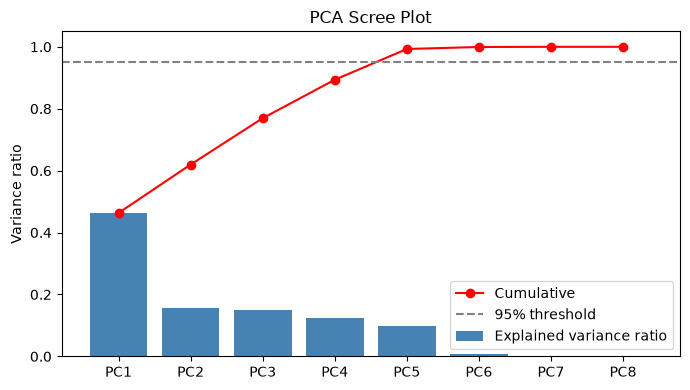

Number of components kept: 5


In [423]:
pca_full = PCA().fit(X_train_s)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

pc_names = [f"PC{i+1}" for i in range(len(feature_cols))]
var_table = pd.DataFrame({"Eigenvalue": pca_full.explained_variance_,
                          "Explained ratio": evr,
                          "Cumulative ratio": cum_evr}, index=pc_names)
print(var_table.to_string())

# Scree plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(pc_names, evr, color="steelblue", label="Explained variance ratio")
ax.plot(pc_names, cum_evr, "o-", color="red", label="Cumulative")
ax.axhline(0.95, color="gray", linestyle="--", label="95% threshold")
ax.set_ylabel("Variance ratio")
ax.set_title("PCA Scree Plot")
ax.legend()
plt.tight_layout()
plt.show()

# Keep the smallest number of components that explains >= 95% of the variance
n_comp = int(np.argmax(cum_evr >= 0.95)) + 1
print("Number of components kept:", n_comp)

### 4C

Loadings of PC1 and PC2:
       PC1     PC2
X1 -0.4967 -0.2060
X2  0.5023  0.1966
X3 -0.0245  0.7791
X4  0.5043 -0.1828
X5 -0.4960  0.1850
X6  0.0000 -0.0288
X7 -0.0065 -0.3567
X8  0.0012 -0.3409

Contribution (%) of each feature:
       PC1     PC2
X1 24.6700  4.2400
X2 25.2300  3.8600
X3  0.0600 60.7000
X4 25.4300  3.3400
X5 24.6000  3.4200
X6  0.0000  0.0800
X7  0.0000 12.7200
X8  0.0000 11.6200


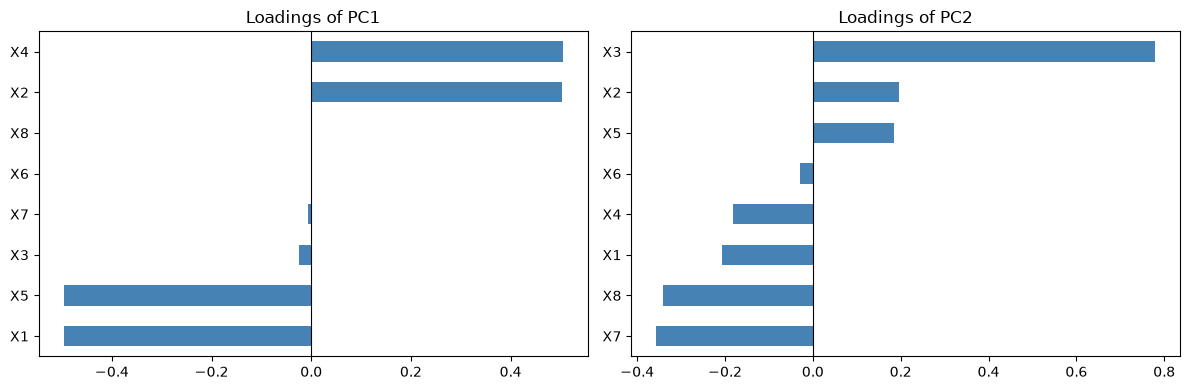

In [424]:
loadings = pd.DataFrame(pca_full.components_.T, index=feature_cols, columns=pc_names)
print("Loadings of PC1 and PC2:")
print(loadings[["PC1", "PC2"]].to_string())

# Contribution (%) of each original feature to PC1 and PC2 = squared loading * 100
contrib = (loadings[["PC1", "PC2"]] ** 2) * 100
print("\nContribution (%) of each feature:")
print(contrib.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    loadings[pc].sort_values().plot.barh(ax=ax, color="steelblue")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Loadings of {pc}")
plt.tight_layout()
plt.show()

### 4D

In [425]:
# Pipeline = StandardScaler -> PCA -> LinearRegression (all fitted on training data only)
pca_model = make_pipeline(StandardScaler(),
                          PCA(n_components=n_comp),
                          LinearRegression()).fit(X_train, y_train_log)

pca_name = f"MLR + PCA ({n_comp} PCs)"
res_pca = evaluate(pca_model, pca_name, n_params=n_comp)
print(res_pca.to_string(index=False))

            Model Split     R2  Adj R2    MAE   RMSE  R2 (log scale)
MLR + PCA (5 PCs) Train 0.8304  0.8290 2.6427 3.8999          0.8855
MLR + PCA (5 PCs)  Test 0.8066  0.8001 2.8714 4.2333          0.8784


In [426]:
# Extra: how does the test performance change with the number of components?
sweep = []
for k in range(1, 8):          # the rank of X is 7, so 7 is the maximum useful number
    mk = make_pipeline(StandardScaler(), PCA(n_components=k),
                       LinearRegression()).fit(X_train, y_train_log)
    pred = np.exp(mk.predict(X_test))
    sweep.append({"n_components": k,
                  "Test R2": r2_score(y_test, pred),
                  "Test RMSE": np.sqrt(mean_squared_error(y_test, pred))})
print(pd.DataFrame(sweep).to_string(index=False))

 n_components  Test R2  Test RMSE
            1   0.5526     6.4383
            2   0.6571     5.6365
            3   0.8056     4.2439
            4   0.8004     4.3003
            5   0.8066     4.2333
            6   0.8894     3.2018
            7   0.8887     3.2120


In [427]:
# Optional 2: what does PC6 contain, and how strongly does it relate to log(Y)?
pca7 = make_pipeline(StandardScaler(), PCA(n_components=7)).fit(X_train)
scores = pd.DataFrame(pca7.transform(X_train), columns=[f"PC{i+1}" for i in range(7)])

print("Correlation of each PC score with log(Y):")
print(scores.corrwith(y_train_log.reset_index(drop=True)).round(3).to_string())
print("\nLoadings of PC6:")
print(pd.Series(pca7[-1].components_[5], index=feature_cols).round(3).to_string())

Correlation of each PC score with log(Y):
PC1   -0.8350
PC2    0.2410
PC3    0.3320
PC4   -0.0410
PC5    0.1380
PC6    0.1790
PC7   -0.0080

Loadings of PC6:
X1   -0.4980
X2    0.0670
X3   -0.2880
X4    0.2050
X5    0.7890
X6    0.0090
X7   -0.0030
X8    0.0030


### 4E

In [428]:
cmp_pca = pd.concat([res_mlr, res_pca], ignore_index=True)
print(cmp_pca[cmp_pca["Split"] == "Test"].to_string(index=False))

            Model Split     R2  Adj R2    MAE   RMSE  R2 (log scale)
   MLR (baseline)  Test 0.8887  0.8825 2.1144 3.2120          0.9234
MLR + PCA (5 PCs)  Test 0.8066  0.8001 2.8714 4.2333          0.8784


### 4F

In [429]:
def calc_vif(df_in):
    Xc = sm.add_constant(df_in, has_constant="add")
    out = pd.DataFrame({"Feature": Xc.columns,
                        "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
    return out[out["Feature"] != "const"].reset_index(drop=True)

# Principal component scores of the training set
Z_train = pca_model[:-1].transform(X_train)
Z_df = pd.DataFrame(Z_train, columns=[f"PC{i+1}" for i in range(n_comp)])

print("Correlation matrix of the PC scores (should be ~ identity):")
print(Z_df.corr().round(3).to_string())

print("\nVIF of the PC scores:")
print(calc_vif(Z_df).to_string(index=False))

print("\nCondition number of the scaled original features:", f"{np.linalg.cond(X_train_s):.3e}")
print("Condition number of the retained PC scores      :", f"{np.linalg.cond(Z_train):.3e}")

Correlation matrix of the PC scores (should be ~ identity):
        PC1     PC2     PC3     PC4     PC5
PC1  1.0000 -0.0000 -0.0000 -0.0000  0.0000
PC2 -0.0000  1.0000  0.0000 -0.0000  0.0000
PC3 -0.0000  0.0000  1.0000 -0.0000 -0.0000
PC4 -0.0000 -0.0000 -0.0000  1.0000  0.0000
PC5  0.0000  0.0000 -0.0000  0.0000  1.0000

VIF of the PC scores:
Feature    VIF
    PC1 1.0000
    PC2 1.0000
    PC3 1.0000
    PC4 1.0000
    PC5 1.0000

Condition number of the scaled original features: 2.833e+15
Condition number of the retained PC scores      : 2.160e+00


### 4G

            Model Split     R2  Adj R2    MAE   RMSE  R2 (log scale)
   MLR (baseline) Train 0.8885  0.8870 2.1404 3.1622          0.9178
   MLR (baseline)  Test 0.8887  0.8825 2.1144 3.2120          0.9234
    Poly degree 2 Train 0.9726  0.9705 1.0464 1.5671          0.9841
    Poly degree 2  Test 0.9664  0.9528 1.2147 1.7648          0.9813
    Poly degree 3 Train 0.9803  0.9731 0.8745 1.3292          0.9884
    Poly degree 3  Test 0.9718     NaN 1.0878 1.6162          0.9844
MLR + PCA (5 PCs) Train 0.8304  0.8290 2.6427 3.8999          0.8855
MLR + PCA (5 PCs)  Test 0.8066  0.8001 2.8714 4.2333          0.8784


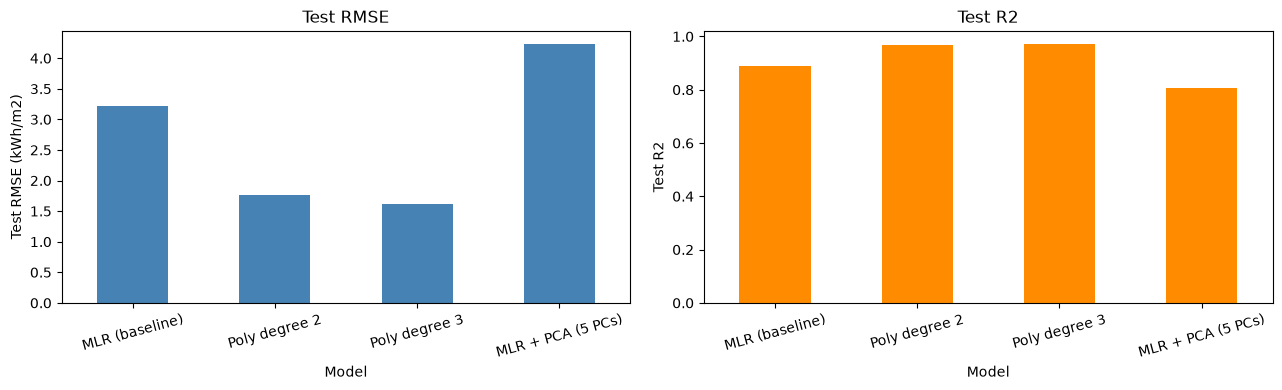

In [430]:
all_res = pd.concat([res_mlr, res_p2, res_p3, res_pca], ignore_index=True)
print(all_res.to_string(index=False))

test_res = all_res[all_res["Split"] == "Test"].set_index("Model")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
test_res["RMSE"].plot.bar(ax=axes[0], color="steelblue", rot=15)
axes[0].set_ylabel("Test RMSE (kWh/m2)"); axes[0].set_title("Test RMSE")
test_res["R2"].plot.bar(ax=axes[1], color="darkorange", rot=15)
axes[1].set_ylabel("Test R2"); axes[1].set_title("Test R2")
plt.tight_layout()
plt.show()

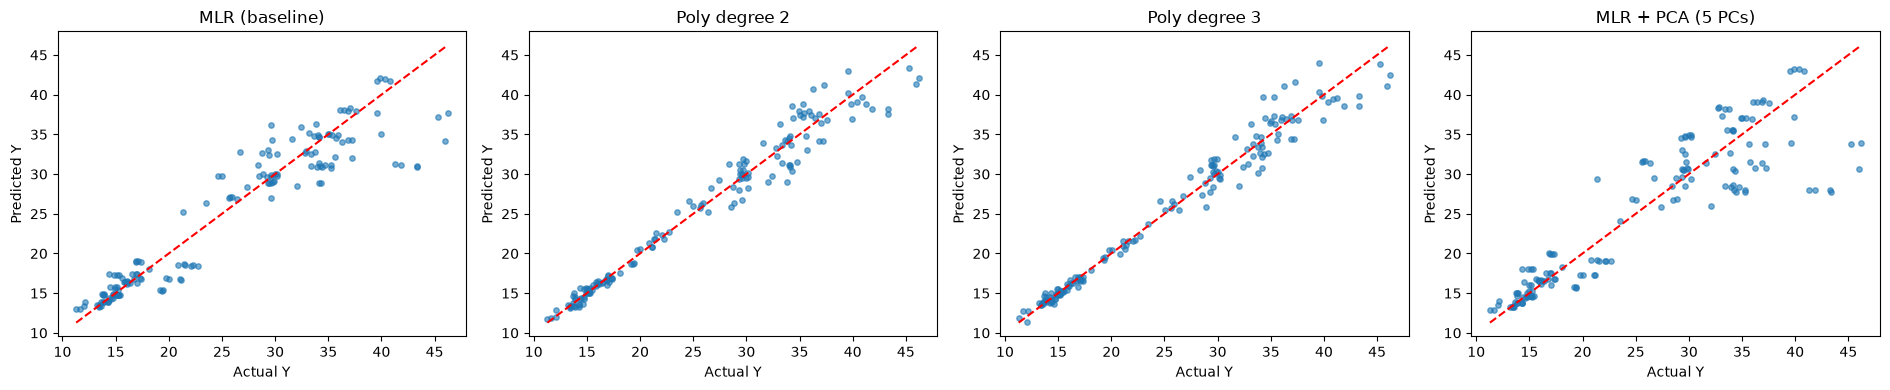

In [431]:
# Actual vs predicted (test set, kWh/m2)
models = {"MLR (baseline)": mlr, "Poly degree 2": poly2,
          "Poly degree 3": poly3, pca_name: pca_model}
lims = [y_test.min(), y_test.max()]

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (name, mdl) in zip(axes, models.items()):
    ax.scatter(y_test, np.exp(mdl.predict(X_test)), alpha=0.6, s=15)
    ax.plot(lims, lims, "r--")
    ax.set_xlabel("Actual Y"); ax.set_ylabel("Predicted Y")
    ax.set_title(name)
plt.tight_layout()
plt.show()

# Part C：Model Deployment

## Step 0: Deployment model selection (robustness check)

In [432]:
import joblib
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.compose import ColumnTransformer

In [433]:
# Energy label (EU-style) based on the Cooling Load ranges given in the task
def energy_grade(y):
    if y <= 15.0:  return "A", "Excellent", "Dark Green"
    if y <= 20.0:  return "B", "Good", "Light Green"
    if y <= 28.0:  return "C", "Average", "Yellow"
    if y <= 35.0:  return "D", "Below Average", "Orange"
    return "E", "Poor", "Red"

# The three building profiles from the task (order = X1 ... X8)
designs = pd.DataFrame({
    "Design A": [0.85, 588.0, 294.0, 147.00, 7.0, 2, 0.25, 3],
    "Design B": [0.65, 784.0, 343.0, 220.50, 3.5, 4, 0.10, 1],
    "Design C": [0.90, 563.5, 318.5, 122.50, 7.0, 3, 0.40, 4],
}, index=feature_cols).T

# Diagnosis check: moving X1 to the nearest training shape should restore sensible values
check = designs[feature_cols].copy()
check.loc["Design A", "X1"] = 0.86
check.loc["Design B", "X1"] = 0.64
print("Poly degree 2 with on-grid X1 (A, B, C):", np.exp(poly2.predict(check)).round(2))

Poly degree 2 with on-grid X1 (A, B, C): [31.33 18.33 36.98]


In [434]:
# X2 identifies the 12 building shapes (one-to-one with X1)
groups_train = X_train["X2"]
logo = LeaveOneGroupOut()

def make_poly_ridge(degree, alpha):
    # second StandardScaler puts all polynomial terms on the same scale before the Ridge penalty
    return make_pipeline(StandardScaler(),
                         PolynomialFeatures(degree=degree, include_bias=False),
                         StandardScaler(),
                         Ridge(alpha=alpha))

def shape_cv_rmse(model):
    """Leave-one-shape-out CV on the training set (RMSE on the log scale).
    The two extreme shapes are extrapolations, so values are pessimistic but comparable across models."""
    scores = cross_val_score(model, X_train, y_train_log, groups=groups_train,
                             cv=logo, scoring="neg_root_mean_squared_error")
    return -scores.mean()

# Tune alpha by leave-one-shape-out CV
alphas = [0.1, 1, 10, 100, 1000]
tuning = pd.DataFrame([{"degree": d, "alpha": a, "Shape-CV RMSE (log)": shape_cv_rmse(make_poly_ridge(d, a))}
                       for d in (2, 3) for a in alphas])
print(tuning.to_string(index=False))

best_alpha = tuning.loc[tuning.groupby("degree")["Shape-CV RMSE (log)"].idxmin()].set_index("degree")["alpha"]
print("\nBest alpha per degree:", best_alpha.to_dict())

poly2_r = make_poly_ridge(2, best_alpha[2]).fit(X_train, y_train_log)
poly3_r = make_poly_ridge(3, best_alpha[3]).fit(X_train, y_train_log)

 degree      alpha  Shape-CV RMSE (log)
      2     0.1000               0.6212
      2     1.0000               0.4435
      2    10.0000               0.2295
      2   100.0000               0.1544
      2 1,000.0000               0.2292
      3     0.1000               0.9498
      3     1.0000               0.9077
      3    10.0000               0.5879
      3   100.0000               0.2654
      3 1,000.0000               0.2225

Best alpha per degree: {2: 100.0, 3: 1000.0}


In [435]:
# Compare all candidates on four criteria
candidates = {"MLR (baseline)": mlr, "Poly degree 2": poly2, "Poly degree 3": poly3,
              "Poly 2 + Ridge": poly2_r, "Poly 3 + Ridge": poly3_r}

# Sensitivity test: shift X1 by +0.01 (an off-grid shape) and see how much the prediction moves
X_jit = X_test.copy()
X_jit["X1"] = X_jit["X1"] + 0.01

rows = []
for name, m in candidates.items():
    p_test = np.exp(m.predict(X_test))
    p_jit = np.exp(m.predict(X_jit))
    p_des = np.exp(m.predict(designs[feature_cols]))
    rows.append({
        "Model": name,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, p_test)),
        "Shape-CV RMSE (log)": shape_cv_rmse(m),
        "X1+0.01 mean |dY|": np.abs(p_jit - p_test).mean(),
        "X1+0.01 max |dY|": np.abs(p_jit - p_test).max(),
        "Design A": p_des[0], "Design B": p_des[1], "Design C": p_des[2],
    })
robust_table = pd.DataFrame(rows)
print(robust_table.round(3).to_string(index=False))
print("\nNearest training rows (actual Y): Design A 33.52 | Design B 19.34 | Design C 39.92")

         Model  Test RMSE  Shape-CV RMSE (log)  X1+0.01 mean |dY|  X1+0.01 max |dY|  Design A  Design B  Design C
MLR (baseline)     3.2120               0.1580             0.3070            0.5220   31.4360   15.0580   35.0870
 Poly degree 2     1.7650              12.9460         3,677.1420       41,542.1580    9.5730    2.9240   36.9800
 Poly degree 3     1.6160               2.6990            52.2780        3,014.1270   32.6040   20.4100   36.8690
Poly 2 + Ridge     3.1260               0.1540             0.0670            0.1460   30.7610   15.5540   34.6750
Poly 3 + Ridge     3.7030               0.2220             0.1960            1.0820   29.3780   16.7700   33.7710

Nearest training rows (actual Y): Design A 33.52 | Design B 19.34 | Design C 39.92


In [436]:
# Use only the non-redundant features: X1 and X2 are derived from the geometry
core_cols = ["X3", "X4", "X5", "X6", "X7", "X8"]

def make_reduced_poly(degree, ridge=False):
    steps = [ColumnTransformer([("keep", "passthrough", core_cols)]),
             StandardScaler(),
             PolynomialFeatures(degree=degree, include_bias=False)]
    if ridge:
        steps += [StandardScaler(), RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10, 100])]
    else:
        steps += [LinearRegression()]
    return make_pipeline(*steps)

reduced = {
    "Poly 2 + Ridge (all features)": poly2_r,
    "Poly 2 reduced": make_reduced_poly(2).fit(X_train, y_train_log),
    "Poly 3 reduced": make_reduced_poly(3).fit(X_train, y_train_log),
    "Poly 2 reduced + Ridge": make_reduced_poly(2, ridge=True).fit(X_train, y_train_log),
    "Poly 3 reduced + Ridge": make_reduced_poly(3, ridge=True).fit(X_train, y_train_log),
}

# Sensitivity test: scale wall and roof area by +1% (surface area recomputed from the identity)
geo_jit = X_test.copy()
geo_jit["X3"] = geo_jit["X3"] * 1.01
geo_jit["X4"] = geo_jit["X4"] * 1.01
geo_jit["X2"] = geo_jit["X3"] + 2 * geo_jit["X4"]

rows = []
for name, m in reduced.items():
    p_test = np.exp(m.predict(X_test))
    p_geo = np.exp(m.predict(geo_jit))
    p_des = np.exp(m.predict(designs[feature_cols]))
    rows.append({"Model": name,
                 "Test R2": r2_score(y_test, p_test),
                 "Test RMSE": np.sqrt(mean_squared_error(y_test, p_test)),
                 "Geo+1% mean |dY|": np.abs(p_geo - p_test).mean(),
                 "Geo+1% max |dY|": np.abs(p_geo - p_test).max(),
                 "Design A": p_des[0], "Design B": p_des[1], "Design C": p_des[2]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nNearest training rows (actual Y): Design A 33.52 | Design B 19.34 | Design C 39.92")

                        Model  Test R2  Test RMSE  Geo+1% mean |dY|  Geo+1% max |dY|  Design A  Design B  Design C
Poly 2 + Ridge (all features)   0.8950     3.1260            0.1690           0.3590   30.7610   15.5540   34.6750
               Poly 2 reduced   0.9210     2.7020            0.6520           1.3100   29.1670   15.2040   37.0670
               Poly 3 reduced   0.9640     1.8240            1.5010           3.8720   31.9080   16.9660   36.8410
       Poly 2 reduced + Ridge   0.9210     2.7020            0.3450           0.9860   29.1750   15.2050   37.0420
       Poly 3 reduced + Ridge   0.9640     1.8230            2.8190           8.1170   31.9010   16.9680   36.8410

Nearest training rows (actual Y): Design A 33.52 | Design B 19.34 | Design C 39.92


In [437]:
# Gate check: leave-one-shape-out CV for the reduced models
for name, m in reduced.items():
    print(f"{name:45s} Shape-CV RMSE (log scale): {shape_cv_rmse(m):.4f}")
print("\nReference: MLR 0.1580 | Poly 2 + Ridge 0.1540 | Poly 3 + Ridge 0.2220")

Poly 2 + Ridge (all features)                 Shape-CV RMSE (log scale): 0.1544
Poly 2 reduced                                Shape-CV RMSE (log scale): 0.2556
Poly 3 reduced                                Shape-CV RMSE (log scale): 0.7780
Poly 2 reduced + Ridge                        Shape-CV RMSE (log scale): 0.2529
Poly 3 reduced + Ridge                        Shape-CV RMSE (log scale): 0.8163

Reference: MLR 0.1580 | Poly 2 + Ridge 0.1540 | Poly 3 + Ridge 0.2220


## TASK 1: Model Persistence & Serialisation (*optional) 

In [438]:
import joblib

# ---- 1) Choose the final model: change ONLY these two lines to switch models ----
best_model_name = "Poly 2 reduced + Ridge"
best_model = reduced["Poly 2 reduced + Ridge"]     # uses only X3-X8; defined in the reduced-model cell

# ---- 2) Compute the metadata BEFORE building the artifact ----
n_params = best_model[-1].coef_.shape[0]
test_metrics = evaluate(best_model, best_model_name, n_params)
test_metrics = test_metrics[test_metrics["Split"] == "Test"].iloc[0].to_dict()

# The pipeline bundles every preprocessing step. The target was log(Y), so the app applies np.exp().
artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_cols": feature_cols,
    "target_transform": "log",
    "train_range": {c: (float(X_train[c].min()), float(X_train[c].max())) for c in feature_cols},
    "known_shapes": X_train[["X3", "X4", "X5"]].drop_duplicates().values.tolist(),   # the 12 building shapes
    "test_metrics": test_metrics,
}
joblib.dump(artifact, "cooling_load_model.joblib")

# ---- 3) Optional: export every pipeline step separately ----
for step_name, step in best_model.named_steps.items():
    joblib.dump(step, f"step_{step_name}.joblib")

# ---- 4) Reload check ----
loaded = joblib.load("cooling_load_model.joblib")
print("Saved model     :", loaded["model_name"])
print("Pipeline steps  :", [name for name, _ in loaded["model"].steps])
print("Reloaded model reproduces predictions:",
      np.allclose(np.exp(best_model.predict(X_test)), np.exp(loaded["model"].predict(X_test))))
print("Designs A, B, C :", np.exp(loaded["model"].predict(designs[feature_cols])).round(2))
print("Test metrics    :", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in loaded["test_metrics"].items()})

Saved model     : Poly 2 reduced + Ridge
Pipeline steps  : ['columntransformer', 'standardscaler-1', 'polynomialfeatures', 'standardscaler-2', 'ridgecv']
Reloaded model reproduces predictions: True
Designs A, B, C : [29.18 15.2  37.04]
Test metrics    : {'Model': 'Poly 2 reduced + Ridge', 'Split': 'Test', 'R2': 0.9212, 'Adj R2': 0.9043, 'MAE': 1.8063, 'RMSE': 2.7022, 'R2 (log scale)': 0.9402}


## TASK 2

### 2A, 2B, 2D–2F: Streamlit app

In [439]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt

st.set_page_config(page_title="Cooling Load Predictor", page_icon="🏢", layout="wide")

# ------------------------------------------------------------------
# Load the trained model (cached so it is only read once)
# ------------------------------------------------------------------
@st.cache_resource
def load_artifact(path="cooling_load_model.joblib"):
    return joblib.load(path)

artifact = load_artifact()
model = artifact["model"]
FEATURES = artifact["feature_cols"]
TRAIN_RANGE = artifact["train_range"]

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
# Hard bounds used for input validation (realistic building ranges)
BOUNDS = {
    "X1": (0.5, 1.0), "X2": (450.0, 850.0), "X3": (200.0, 450.0), "X4": (100.0, 250.0),
    "X5": (3.5, 7.0), "X6": (2, 5), "X7": (0.0, 0.5), "X8": (0, 5),
}
ORIENTATION = {2: "2 (North)", 3: "3 (East)", 4: "4 (South)", 5: "5 (West)"}

# European Union energy label scale: (upper limit, grade, performance, colour name, hex)
GRADES = [
    (15.0, "A", "Excellent", "Dark Green", "#006400"),
    (20.0, "B", "Good", "Light Green", "#7ED957"),
    (28.0, "C", "Average", "Yellow", "#FFD700"),
    (35.0, "D", "Below Average", "Orange", "#FFA500"),
    (float("inf"), "E", "Poor", "Red", "#E53935"),
]
RANGE_TEXT = ["Y <= 15.0", "15.0 < Y <= 20.0", "20.0 < Y <= 28.0", "28.0 < Y <= 35.0", "Y > 35.0"]

PRESETS = {
    "Custom": None,
    "Design A": dict(X1=0.85, X2=588.0, X3=294.0, X4=147.0, X5=7.0, X6=2, X7=0.25, X8=3),
    "Design B": dict(X1=0.65, X2=784.0, X3=343.0, X4=220.5, X5=3.5, X6=4, X7=0.10, X8=1),
    "Design C": dict(X1=0.90, X2=563.5, X3=318.5, X4=122.5, X5=7.0, X6=3, X7=0.40, X8=4),
}

# ------------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------------
def predict_cooling_load(values):
    """Predict log(Y) with the saved pipeline, then back-transform with exp() to kWh/m2."""
    row = pd.DataFrame([[values[c] for c in FEATURES]], columns=FEATURES)
    log_pred = model.predict(row)[0]
    return float(np.exp(log_pred))

def energy_grade(y):
    for upper, grade, perf, colour_name, hex_code in GRADES:
        if y <= upper:
            return grade, perf, colour_name, hex_code

def validate(v):
    """Return (errors, warnings). Errors block the prediction; warnings do not."""
    errors, warns = [], []
    for k, (lo, hi) in BOUNDS.items():
        if not lo <= v[k] <= hi:
            errors.append(f"{k} = {v[k]} is outside the allowed range [{lo}, {hi}].")
    # Geometry: surface area = wall area + 2 * roof area
    expected = v["X3"] + 2 * v["X4"]
    if abs(v["X2"] - expected) > 1.0:
        errors.append(f"Geometry check failed: Surface Area (X2 = {v['X2']:.1f}) must equal "
                      f"Wall Area + 2 x Roof Area (X3 + 2*X4 = {expected:.1f}).")
    # Glazing consistency (as in the training data)
    if v["X7"] <= 1e-9 and v["X8"] != 0:
        errors.append("If Glazing Area (X7) is 0, Glazing Area Distribution (X8) must be 0.")
    if v["X7"] > 1e-9 and v["X8"] == 0:
        errors.append("If Glazing Area (X7) > 0, choose a Glazing Area Distribution (X8) from 1 to 5.")
    # Soft warning: outside the range the model was trained on
    for k, (lo, hi) in TRAIN_RANGE.items():
        if not lo <= v[k] <= hi:
            warns.append(f"{k} = {v[k]} is outside the training range [{lo:.2f}, {hi:.2f}]; "
                         "the prediction is an extrapolation.")
        # Soft warning: the model uses X3-X8; check that the building shape was seen in training
    shapes = artifact.get("known_shapes", [])
    if shapes and min(abs(v["X3"] - a) + abs(v["X4"] - b) + abs(v["X5"] - c) for a, b, c in shapes) > 0.5:
        warns.append("This wall / roof / height combination does not match any of the 12 building shapes "
                     "in the training data; the prediction interpolates between shapes and is less reliable.")
    return errors, warns

def draw_gauge(y):
    xmax = max(50.0, y * 1.1)
    edges = [0, 15, 20, 28, 35, xmax]
    fig, ax = plt.subplots(figsize=(8, 1.9))
    for i, (_, grade, _, _, hex_code) in enumerate(GRADES):
        lo, hi = edges[i], edges[i + 1]
        ax.barh(0, hi - lo, left=lo, height=0.5, color=hex_code, edgecolor="white")
        ax.text((lo + hi) / 2, 0, grade, ha="center", va="center", fontsize=14, fontweight="bold")
    ax.plot([y], [0.38], marker="v", markersize=14, color="black")
    ax.text(y, 0.55, f"{y:.1f} kWh/m2", ha="center", va="bottom", fontweight="bold")
    ax.set_xlim(0, xmax)
    ax.set_ylim(-0.4, 0.95)
    ax.set_yticks([])
    ax.set_xlabel("Cooling Load (kWh/m2)")
    for side in ["left", "right", "top"]:
        ax.spines[side].set_visible(False)
    return fig

def apply_preset():
    preset = PRESETS[st.session_state["preset"]]
    if preset is not None:
        for k, val in preset.items():
            st.session_state[k] = val

# Default values = Design A
for k, val in PRESETS["Design A"].items():
    st.session_state.setdefault(k, val)

# ------------------------------------------------------------------
# Sidebar
# ------------------------------------------------------------------
st.sidebar.header("Example designs")
st.sidebar.selectbox("Load an example design", list(PRESETS), key="preset", on_change=apply_preset)

st.sidebar.header("Energy label scale")
st.sidebar.dataframe(pd.DataFrame({
    "Grade": [g[1] for g in GRADES],
    "Cooling Load (kWh/m2)": RANGE_TEXT,
    "Performance": [g[2] for g in GRADES],
    "Colour": [g[3] for g in GRADES],
}), hide_index=True)

# ------------------------------------------------------------------
# Main page
# ------------------------------------------------------------------
st.title("Building Cooling Load Predictor")
st.caption(f"Model: {artifact['model_name']}. It is trained on log(Y); "
           "predictions are back-transformed with exp() to kWh/m2.")
st.caption("X1 and X2 are derived from the building geometry (X2 = X3 + 2*X4, and X1 is fixed by the shape), "
           "so the model uses X3-X8; X2 is still checked for consistency.")
           
left, right = st.columns([1, 1.2])

with left:
    st.subheader("Building parameters")
    st.slider("Relative Compactness (X1)", 0.5, 1.0, step=0.01, key="X1")
    st.number_input("Surface Area (X2, m2)", 450.0, 850.0, step=0.5, format="%.2f", key="X2")
    st.number_input("Wall Area (X3, m2)", 200.0, 450.0, step=0.5, format="%.2f", key="X3")
    st.number_input("Roof Area (X4, m2)", 100.0, 250.0, step=0.25, format="%.2f", key="X4")
    st.selectbox("Overall Height (X5, m)", [3.5, 7.0], key="X5")
    st.selectbox("Orientation (X6)", [2, 3, 4, 5], format_func=lambda o: ORIENTATION[o], key="X6")
    st.slider("Glazing Area (X7)", 0.0, 0.5, step=0.05, key="X7")
    st.selectbox("Glazing Area Distribution (X8)", [0, 1, 2, 3, 4, 5], key="X8")
    predict_clicked = st.button("Predict Cooling Load", type="primary")

values = {k: st.session_state[k] for k in FEATURES}

with right:
    st.subheader("Result")
    if predict_clicked:
        errors, warns = validate(values)
        if errors:
            for e in errors:
                st.error(e)
        else:
            for w in warns:
                st.warning(w)
            y_pred = predict_cooling_load(values)
            grade, perf, colour_name, hex_code = energy_grade(y_pred)
            text_colour = "white" if grade in ("A", "E") else "black"

            st.metric("Predicted Cooling Load", f"{y_pred:.2f} kWh/m2")
            st.markdown(
                f"""<div style="background:{hex_code};padding:18px;border-radius:12px;text-align:center;">
                <span style="font-size:42px;font-weight:700;color:{text_colour};">Grade {grade}</span><br>
                <span style="font-size:20px;color:{text_colour};">{perf} ({colour_name})</span></div>""",
                unsafe_allow_html=True,
            )
            fig = draw_gauge(y_pred)
            st.pyplot(fig)
            plt.close(fig)
    else:
        st.info("Set the building parameters and click 'Predict Cooling Load'.")

    with st.expander("Predictions for the three example designs"):
        rows = []
        for name, p in PRESETS.items():
            if p is None:
                continue
            y_hat = predict_cooling_load(p)
            g, perf, _, _ = energy_grade(y_hat)
            rows.append({"Design": name, "Predicted Cooling Load (kWh/m2)": round(y_hat, 2),
                         "Grade": g, "Performance": perf})
        st.dataframe(pd.DataFrame(rows), hide_index=True)

Overwriting app.py


### 2C: Predictions for the three designs

In [440]:
# Predict log(Y), then back-transform with np.exp() to kWh/m2
loaded = joblib.load("cooling_load_model.joblib")
designs["Predicted Y (kWh/m2)"] = np.exp(loaded["model"].predict(designs[feature_cols]))
designs["Poly degree 3 (check)"] = np.exp(poly3.predict(designs[feature_cols]))
designs[["Grade", "Performance", "Colour"]] = [energy_grade(v) for v in designs["Predicted Y (kWh/m2)"]]

print(designs[["Predicted Y (kWh/m2)", "Poly degree 3 (check)", "Grade", "Performance", "Colour"]].round(2).to_string())

          Predicted Y (kWh/m2)  Poly degree 3 (check) Grade    Performance       Colour
Design A               29.1800                32.6000     D  Below Average       Orange
Design B               15.2000                20.4100     B           Good  Light Green
Design C               37.0400                36.8700     E           Poor          Red
